# 03 – LightGBM v1 against persistence

DK1 `SatisfiedDemand`, every ISP of the last 20 % of the window from 1 Oct 2025, per horizon. The models here were fitted on the first 60 % and calibrated on the next 20 %. **The hyperparameters were chosen on this same 20 %**, so the model's rows are optimistic by that choice. Every input is an estimated vintage: this is not the record. The replay (step 5) and the live record are the honest tests.

In [1]:
import json
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nordcast import model

D, M = Path("../data/training"), Path("../data/models")
NAVY, BLUE, GREY, BAND = "#0F2A4A", "#1F5FBF", "#7D8996", "#DCE3EC"
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": BAND,
    }
)
manifest = json.loads((M / "manifest.json").read_text())
rows, preds = [], {}
for h in (15, 30, 60):
    df = pd.read_parquet(D / f"h{h}.parquet")
    _, _, val = model.split(df)
    m = pickle.loads((M / f"holdout-h{h}.pkl").read_bytes())
    pred = m.predict(val)
    preds[h] = (val, pred, m)
    rows.append({"h": h, "method": "lightgbm-v1", **model.score_frame(val, pred)})
    rows.append(
        {
            "h": h,
            "method": "persistence",
            **model.score_frame(val, model.persistence_frame(val)),
        }
    )
    # direction only: the fit period's class shares as constant probabilities
    fit, _, _ = model.split(df)
    shares = fit.y_dir.value_counts(normalize=True)
    const = pd.DataFrame(
        {
            "q10": np.nan,
            "q50": np.nan,
            "q90": np.nan,
            **{f"p_{c}": shares.get(c, 0.0) for c in model.CLASSES},
        },
        index=val.index,
    )
    r = model.score_frame(val, const)
    rows.append(
        {
            "h": h,
            "method": "constant shares (direction)",
            **{
                k: (r[k] if k in ("n", "direction_acc", "brier", "pnl_eur") else np.nan)
                for k in r
            },
        }
    )
card = pd.DataFrame(rows).set_index(["h", "method"])
print(
    f"validation: {val.target.min():%d %b %Y} – {val.target.max():%d %b %Y}, {len(val)} ISPs per horizon"
)
card.round(
    {
        "mae": 1,
        "pinball": 1,
        "coverage": 3,
        "direction_acc": 3,
        "brier": 3,
        "pnl_eur": 0,
    }
)

validation: 10 Aug 2026 – 27 Oct 2026, 7522 ISPs per horizon


n    mae  pinball  coverage  direction_acc  \
h  method                                                                       
15 lightgbm-v1                  7522   98.8     33.2     0.846          0.444   
   persistence                  7522  126.8     42.4     0.798          0.435   
   constant shares (direction)  7522    NaN      NaN       NaN          0.420   
30 lightgbm-v1                  7522   98.9     33.4     0.845          0.427   
   persistence                  7522  130.8     43.8     0.796          0.422   
   constant shares (direction)  7522    NaN      NaN       NaN          0.420   
60 lightgbm-v1                  7522  101.6     34.3     0.853          0.424   
   persistence                  7522  135.5     45.5     0.796          0.406   
   constant shares (direction)  7522    NaN      NaN       NaN          0.420   

                                brier   pnl_eur  
h  method                                        
15 lightgbm-v1                  0.662  125757.0  
   persistence                  1.130  248786.0  
   constant shares (direction)  0.691  -12967.0  
30 lightgbm-v1                  0.671   25187.0  
   persistence                  1.155  202746.0  
   constant shares (direction)  0.691  -12967.0  
60 lightgbm-v1                  0.681  -13305.0  
   persistence                  1.188  142300.0  
   constant shares (direction)  0.691  -12967.0

MAE and pinball (mean over q10/q50/q90) in MW. Coverage: share of first prints inside q10–q90, target 0.80. Brier over three classes; persistence puts all its weight on the last known direction. P&L: 10 MW left open in the called direction for each ISP, settled at the first-print imbalance price against day-ahead, EUR summed over the period (no costs, no limits, a translation of the call and not a strategy). Persistence's one-hot direction makes its Brier score harsh, so the fair bar for direction is the constant-shares row: the fit period's class frequencies.

In [2]:
skill = pd.DataFrame(
    {
        h: {
            "pinball": 1
            - card.loc[(h, "lightgbm-v1"), "pinball"]
            / card.loc[(h, "persistence"), "pinball"],
            "mae": 1
            - card.loc[(h, "lightgbm-v1"), "mae"] / card.loc[(h, "persistence"), "mae"],
            "brier vs persistence": 1
            - card.loc[(h, "lightgbm-v1"), "brier"]
            / card.loc[(h, "persistence"), "brier"],
            "brier vs constant shares": 1
            - card.loc[(h, "lightgbm-v1"), "brier"]
            / card.loc[(h, "constant shares (direction)"), "brier"],
        }
        for h in (15, 30, 60)
    }
).T
skill.round(3)  # skill vs persistence: 0.10 = 10 % lower loss

,pinball,mae,brier vs persistence,brier vs constant shares
15,0.218,0.221,0.414,0.042
30,0.237,0.244,0.419,0.029
60,0.245,0.251,0.426,0.014


## Interval: raw quantiles against the conformal band

In [3]:
pd.DataFrame(
    {
        h: {
            "raw q10-q90": float(np.mean((v.y >= p.q10_raw) & (v.y <= p.q90_raw))),
            "conformal (MAPIE)": float(np.mean((v.y >= p.q10) & (v.y <= p.q90))),
        }
        for h, (v, p, _) in preds.items()
    }
).T.round(3)

,raw q10-q90,conformal (MAPIE)
15,0.847,0.846
30,0.837,0.845
60,0.856,0.853


## Direction calibration, 15 min

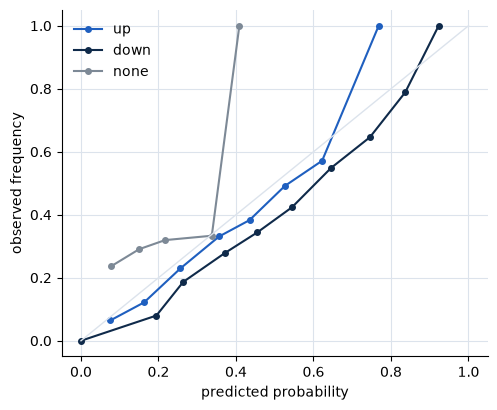

In [4]:
val, pred, _ = preds[15]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for cls, colour in (("up", BLUE), ("down", NAVY), ("none", GREY)):
    p = pred[f"p_{cls}"]
    bins = pd.cut(p, np.linspace(0, 1, 11), include_lowest=True)
    obs = (val.y_dir == cls).groupby(bins, observed=True).mean()
    mid = p.groupby(bins, observed=True).mean()
    ax.plot(mid, obs, "o-", color=colour, label=cls, ms=4)
ax.plot([0, 1], [0, 1], color=BAND, lw=1)
ax.set_xlabel("predicted probability")
ax.set_ylabel("observed frequency")
ax.legend(frameon=False)

## What the 15-minute volume model leans on

In [5]:
_, _, m = preds[15]
imp = pd.Series(
    m.quantile[0.5].booster_.feature_importance("gain"), index=m.feature_names
)
(imp / imp.sum()).sort_values(ascending=False).head(12).round(3)

sd_lag1                         0.355
wind_onshore_err_da_last        0.091
wind_offshore_err_da_last       0.066
solar_fc_da                     0.060
hour                            0.053
wind_onshore_fc_da              0.050
da_price                        0.044
regime_activated                0.038
sd_mean4                        0.033
wind_onshore_fc_1h              0.020
sd_std8                         0.018
wind_offshore_fc_1h_minus_da    0.018
dtype: float64

## Settings chosen and artefacts

In [6]:
pd.DataFrame({h: v["params"] for h, v in manifest["models"].items()}).T

,volume,direction
h15,"{'num_leaves': 7, 'n_estimators': 150, 'learni...","{'num_leaves': 7, 'n_estimators': 150, 'learni..."
h30,"{'num_leaves': 7, 'n_estimators': 150, 'learni...","{'num_leaves': 7, 'n_estimators': 150, 'learni..."
h60,"{'num_leaves': 7, 'n_estimators': 150, 'learni...","{'num_leaves': 15, 'n_estimators': 150, 'learn..."
